# Projeto 3 | Classificação de objetos com ResNet-50

## Problema e critérios experimentais

Neste experimento, testamos se as características aprendidas em ImageNet permitem classificar os objetos de `pavansanagapati/images-dataset` treinando apenas uma nova cabeça. A avaliação se limita ao corpus e à divisão usada; não mede a robustez em outros dados.

Mantemos a ResNet-50 pré-treinada congelada e treinamos somente a camada final. A auditoria identifica as classes e define `QUANTIDADE_CLASSES`, sem lista manual. Escolhemos o estado pela accuracy de validação e preservamos o teste até a avaliação final.

Apresentamos curvas de loss e accuracy de treino e validação, accuracy global e por classe no teste, relatório de classificação e matriz de confusão rotulada. A execução salva auditou 1.803 imagens em sete classes e usou 1.261 imagens de treino, 271 de validação e 271 de teste. A execução v2 obteve 99.6310% no teste (270/271 acertos). Esse valor se refere à divisão fixa avaliada.
### Roteiro e evidências da rubrica

Execute as células em ordem. Os valores e as observações nos textos vêm da execução salva e precisam ser atualizados depois de um novo treino. As propostas de melhoria são hipóteses; nenhuma foi aplicada ao baseline.

| Item do grupo 1 da rubrica | Evidência |
|---|---|
| CNN pré-treinada, cabeça substituída e backbone congelado | Seções 5 e 6: modelo, parâmetros treináveis e BatchNorm em avaliação |
| Curvas e accuracy global/por classe | Seções 6 e 7: histórico, curvas, métricas e matriz de confusão |
| Três estratégias de augmentation justificadas | Seção 8: flip, rotação, cor e escala com justificativas para este domínio |
| Feature extraction versus fine-tuning | Seção 8: decisão por tamanho e proximidade com ImageNet |
| Escolha do modelo, classes e hardware | Seção 5: sete classes observadas e GPU local, conforme a dispensa de T4 |

Este notebook cobre o grupo de CNNs. As atividades de Attention/ViT, CLIP e GANs estão nos outros projetos e devem ser conferidas em seus respectivos notebooks.


## Requisitos e planejamento da execução local

| Recurso | Requisito / estimativa |
|---|---|
| RAM disponível recomendada | 8 GB |
| VRAM para a configuração padrão | 4 GB (6 GB recomendados) |
| Tempo estimado com dados e pesos em cache | 3–15 minutos |
| Hardware de referência | NVIDIA GeForce RTX 3050 Laptop, 6 GB de VRAM, Windows, Python 3.12 |
| Protocolo considerado | ResNet-50 congelada, batch 32, até 20 épocas com early stopping |

Os valores são estimativas de planejamento, não medições de pico nem garantias de tempo. Feche aplicações que ocupem a GPU. Download inicial, armazenamento, outras cargas e early stopping alteram a duração. Instale as dependências de `requirements.txt` na pasta desta atividade e selecione o kernel local. Execute a partir dessa pasta; não há requisito de T4/Colab.


## 1. Ambiente local e reprodutibilidade

Importamos as dependências e fixamos a semente antes da divisão dos dados. Também registramos a GPU e a versão do PyTorch. O treino e a coleta de suas métricas de tempo e memória requerem CUDA local.

A execução salva usou NVIDIA GeForce RTX 3050 6GB Laptop GPU e PyTorch 2.9.0+cu130. A semente controla fontes de aleatoriedade, mas as opções de desempenho do cuDNN não garantem reprodução bit a bit. Não há requisito de execução em T4/Colab.

In [1]:
import copy
import os
import random
import time
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50
from tqdm.auto import tqdm

SEMENTE_ALEATORIA = 42
random.seed(SEMENTE_ALEATORIA)
np.random.seed(SEMENTE_ALEATORIA)
torch.manual_seed(SEMENTE_ALEATORIA)
torch.cuda.manual_seed_all(SEMENTE_ALEATORIA)
# Prioriza a velocidade. Para reproduzir bit a bit, use deterministic=True e benchmark=False.
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

if not torch.cuda.is_available():
    raise RuntimeError("CUDA não está disponível no ambiente local. Este treino e sua telemetria requerem uma GPU CUDA.")

DISPOSITIVO = torch.device("cuda")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"PyTorch: {torch.__version__} | CUDA disponível: {torch.cuda.is_available()}")


GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
PyTorch: 2.9.0+cu130 | CUDA disponível: True


c:\workspace\python\projeto-3-modulo-2\.venv\Lib\site-packages\torch\__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:85.)
  _C._set_float32_matmul_precision(precision)


## 2. Download e localização dinâmica

O KaggleHub retorna o diretório da versão baixada. Procuramos nesse diretório uma coleção com exatamente 1.803 imagens em subpastas de classe e escolhemos a raiz de forma determinística. Para cada arquivo, registramos caminho, pasta candidata a classe e extensão. Caminhos locais e nomes de classes são descobertos nessa busca.

In [2]:
EXTENSOES_IMAGENS = {".jpg", ".jpeg", ".png", ".bmp"}
QUANTIDADE_IMAGENS_ESPERADA = 1803

raiz_dataset = Path(kagglehub.dataset_download("pavansanagapati/images-dataset"))

def coletar_imagens_classes(raiz_candidata):
    registros = []
    for diretorio_classe in sorted(caminho for caminho in raiz_candidata.iterdir() if caminho.is_dir()):
        for caminho in sorted(diretorio_classe.iterdir()):
            if caminho.is_file() and caminho.suffix.lower() in EXTENSOES_IMAGENS:
                registros.append((caminho, diretorio_classe.name))
    return registros

raizes_candidatas = [raiz_dataset] + sorted(caminho for caminho in raiz_dataset.rglob("*") if caminho.is_dir())
colecoes_candidatas = []
for raiz_candidata in raizes_candidatas:
    registros = coletar_imagens_classes(raiz_candidata)
    if registros:
        colecoes_candidatas.append((raiz_candidata, registros))

colecoes_compativeis = [
    (raiz_candidata, registros)
    for raiz_candidata, registros in colecoes_candidatas
    if len(registros) == QUANTIDADE_IMAGENS_ESPERADA and len({nome_classe for _, nome_classe in registros}) >= 2
]
if not colecoes_compativeis:
    diagnosticos = sorted(
        ((str(raiz_candidata), len(registros), len({nome_classe for _, nome_classe in registros}))
        for raiz_candidata, registros in colecoes_candidatas),
        key=lambda elemento: elemento[1],
        reverse=True,
    )[:10]
    raise ValueError(
        f"Não foi encontrada uma coleção de exatamente {QUANTIDADE_IMAGENS_ESPERADA} imagens em subpastas de classe. "
        f"Candidatas (raiz, imagens, classes): {diagnosticos}"
    )

colecoes_compativeis.sort(key=lambda elemento: (len(elemento[0].parts), str(elemento[0])))
raiz_imagens, registros_imagens = colecoes_compativeis[0]
if len(colecoes_compativeis) > 1:
    print("Foram encontradas múltiplas coleções compatíveis; raiz selecionada de forma determinística:")
    for raiz_candidata, registros in colecoes_compativeis:
        print(f"- {raiz_candidata} ({len(registros)} imagens)")


Foram encontradas múltiplas coleções compatíveis; raiz selecionada de forma determinística:
- C:\Users\lord_\.cache\kagglehub\datasets\pavansanagapati\images-dataset\versions\1\data (1803 imagens)
- C:\Users\lord_\.cache\kagglehub\datasets\pavansanagapati\images-dataset\versions\1\data\data (1803 imagens)


### Catálogo das imagens

Registramos caminho, classe indicada pela pasta e extensão. Conferimos o catálogo antes de dividir os dados.

In [3]:
dados_imagens = pd.DataFrame(
    {
        "path": [str(caminho.resolve()) for caminho, _ in registros_imagens],
        "class_name": [nome_classe for _, nome_classe in registros_imagens],
        "extension": [caminho.suffix.lower() for caminho, _ in registros_imagens],
    }
)

print(f"Diretório retornado pelo KaggleHub: {raiz_dataset}")
print(f"Raiz de imagens selecionada: {raiz_imagens}")
print(f"Arquivos de imagem localizados: {len(dados_imagens)}")
display(dados_imagens.head())


Diretório retornado pelo KaggleHub: C:\Users\lord_\.cache\kagglehub\datasets\pavansanagapati\images-dataset\versions\1
Raiz de imagens selecionada: C:\Users\lord_\.cache\kagglehub\datasets\pavansanagapati\images-dataset\versions\1\data
Arquivos de imagem localizados: 1803


,path,class_name,extension
0,C:\Users\lord_\.cache\kagglehub\datasets\pavan...,bike,.bmp
1,C:\Users\lord_\.cache\kagglehub\datasets\pavan...,bike,.bmp
2,C:\Users\lord_\.cache\kagglehub\datasets\pavan...,bike,.bmp
3,C:\Users\lord_\.cache\kagglehub\datasets\pavan...,bike,.bmp
4,C:\Users\lord_\.cache\kagglehub\datasets\pavan...,bike,.bmp


## 3. Auditoria de imagens e classes

Antes de dividir os dados, conferimos os 1.803 caminhos únicos, a leitura e a conversão das imagens para RGB e o mínimo de duas amostras por classe. Se o mesmo rótulo aparecer em diretórios físicos diferentes, rejeitamos a estrutura, pois a classe derivada da pasta ficaria ambígua. A auditoria define a lista de classes.

Na execução salva, foram confirmadas 1.803 imagens legíveis e convertíveis para RGB: `bike` (365), `cars` (420), `cats` (202), `dogs` (202), `flowers` (210), `horses` (202) e `human` (202). Carros e bicicletas têm mais exemplos que as demais classes. As larguras variam de 80 a 1.920 pixels, e as alturas, de 89 a 2.048 pixels.

A galeria mostra três exemplos por classe. Bicicletas e carros aparecem ao ar livre, em diferentes orientações e distâncias. Gatos e cães têm enquadramentos e fundos variados; flores diferem em cor e forma. Também vemos uma figura decorativa em `cats`, uma ilustração em `horses` e uma pessoa junto a um cavalo em `human`. A amostra sugere variedade de representação e coexistência de objetos, mas não comprova erros de rótulo nem explica o erro de teste.

In [4]:
if len(dados_imagens) != QUANTIDADE_IMAGENS_ESPERADA:
    raise ValueError(f"Contrato violado: esperadas {QUANTIDADE_IMAGENS_ESPERADA} imagens, encontradas {len(dados_imagens)}.")
if not dados_imagens.path.is_unique:
    raise ValueError("Contrato violado: há caminhos de imagem duplicados.")
if dados_imagens.class_name.isna().any() or (dados_imagens.class_name.str.strip() == "").any():
    raise ValueError("Contrato violado: há rótulo de classe vazio ou ausente.")

diretorios_classes = (
    dados_imagens.assign(class_dir=dados_imagens.path.map(lambda valor: str(Path(valor).parent)))
    .groupby("class_name")["class_dir"].nunique()
)
classes_ambiguas = diretorios_classes[diretorios_classes > 1]
if not classes_ambiguas.empty:
    raise ValueError(
        "Estrutura ambígua: o mesmo nome de classe aparece em múltiplos diretórios: "
        + ", ".join(classes_ambiguas.index.tolist())
    )

arquivos_invalidos = []
tamanhos_imagens = []
for texto_caminho in tqdm(dados_imagens.path, desc="Validando imagens"):
    caminho = Path(texto_caminho)
    try:
        with Image.open(caminho) as imagem:
            imagem.verify()
        with Image.open(caminho) as imagem:
            imagem.convert("RGB")
            tamanhos_imagens.append(imagem.size)
    except (OSError, UnidentifiedImageError, ValueError) as error:
        arquivos_invalidos.append(f"{caminho}: {error}")

if arquivos_invalidos:
    raise ValueError("Foram encontradas imagens ilegíveis ou não conversíveis para RGB: \n" + "\n".join(arquivos_invalidos[:10]))

contagens_classes = dados_imagens.class_name.value_counts().sort_index()
if (contagens_classes < 2).any():
    raise ValueError("Contrato violado: cada classe precisa de ao menos duas imagens. Classes inválidas: " + ", ".join(contagens_classes[contagens_classes < 2].index))

NOMES_CLASSES = sorted(dados_imagens.class_name.unique())
QUANTIDADE_CLASSES = len(NOMES_CLASSES)
CLASSE_PARA_INDICE = {nome_classe: indice_classe for indice_classe, nome_classe in enumerate(NOMES_CLASSES)}
INDICE_PARA_CLASSE = {indice_classe: nome_classe for nome_classe, indice_classe in CLASSE_PARA_INDICE.items()}
dados_imagens["class_id"] = dados_imagens.class_name.map(CLASSE_PARA_INDICE)
dados_imagens["width"] = [largura for largura, _ in tamanhos_imagens]
dados_imagens["height"] = [altura for _, altura in tamanhos_imagens]


Validando imagens:   0%|          | 0/1803 [00:00<?, ?it/s]

### Resultado da auditoria

Mostramos as classes, extensões e dimensões encontradas. Os nomes das classes vêm dos dados, sem lista manual.

In [5]:
print(f"Auditoria concluída: {len(dados_imagens)} imagens RGB legíveis em {QUANTIDADE_CLASSES} classes.")
print("Classes descobertas:", NOMES_CLASSES)
display(contagens_classes.rename("count").to_frame())
display(dados_imagens.groupby("extension").size().rename("count").to_frame())
display(dados_imagens[["width", "height"]].describe())


Auditoria concluída: 1803 imagens RGB legíveis em 7 classes.
Classes descobertas: ['bike', 'cars', 'cats', 'dogs', 'flowers', 'horses', 'human']


,count
class_name,
bike,365
cars,420
cats,202
dogs,202
flowers,210
horses,202
human,202


,count
extension,
.bmp,785
.jpg,808
.png,210


,width,height
count,1803.000000,1803.000000
mean,439.412091,362.491958
std,218.313344,156.510932
min,80.000000,89.000000
25%,225.000000,225.000000
50%,499.000000,403.000000
75%,640.000000,480.000000
max,1920.000000,2048.000000


### Galeria por classe

Exibimos três imagens por classe, escolhidas com semente fixa. As observações se referem apenas a essa amostra.

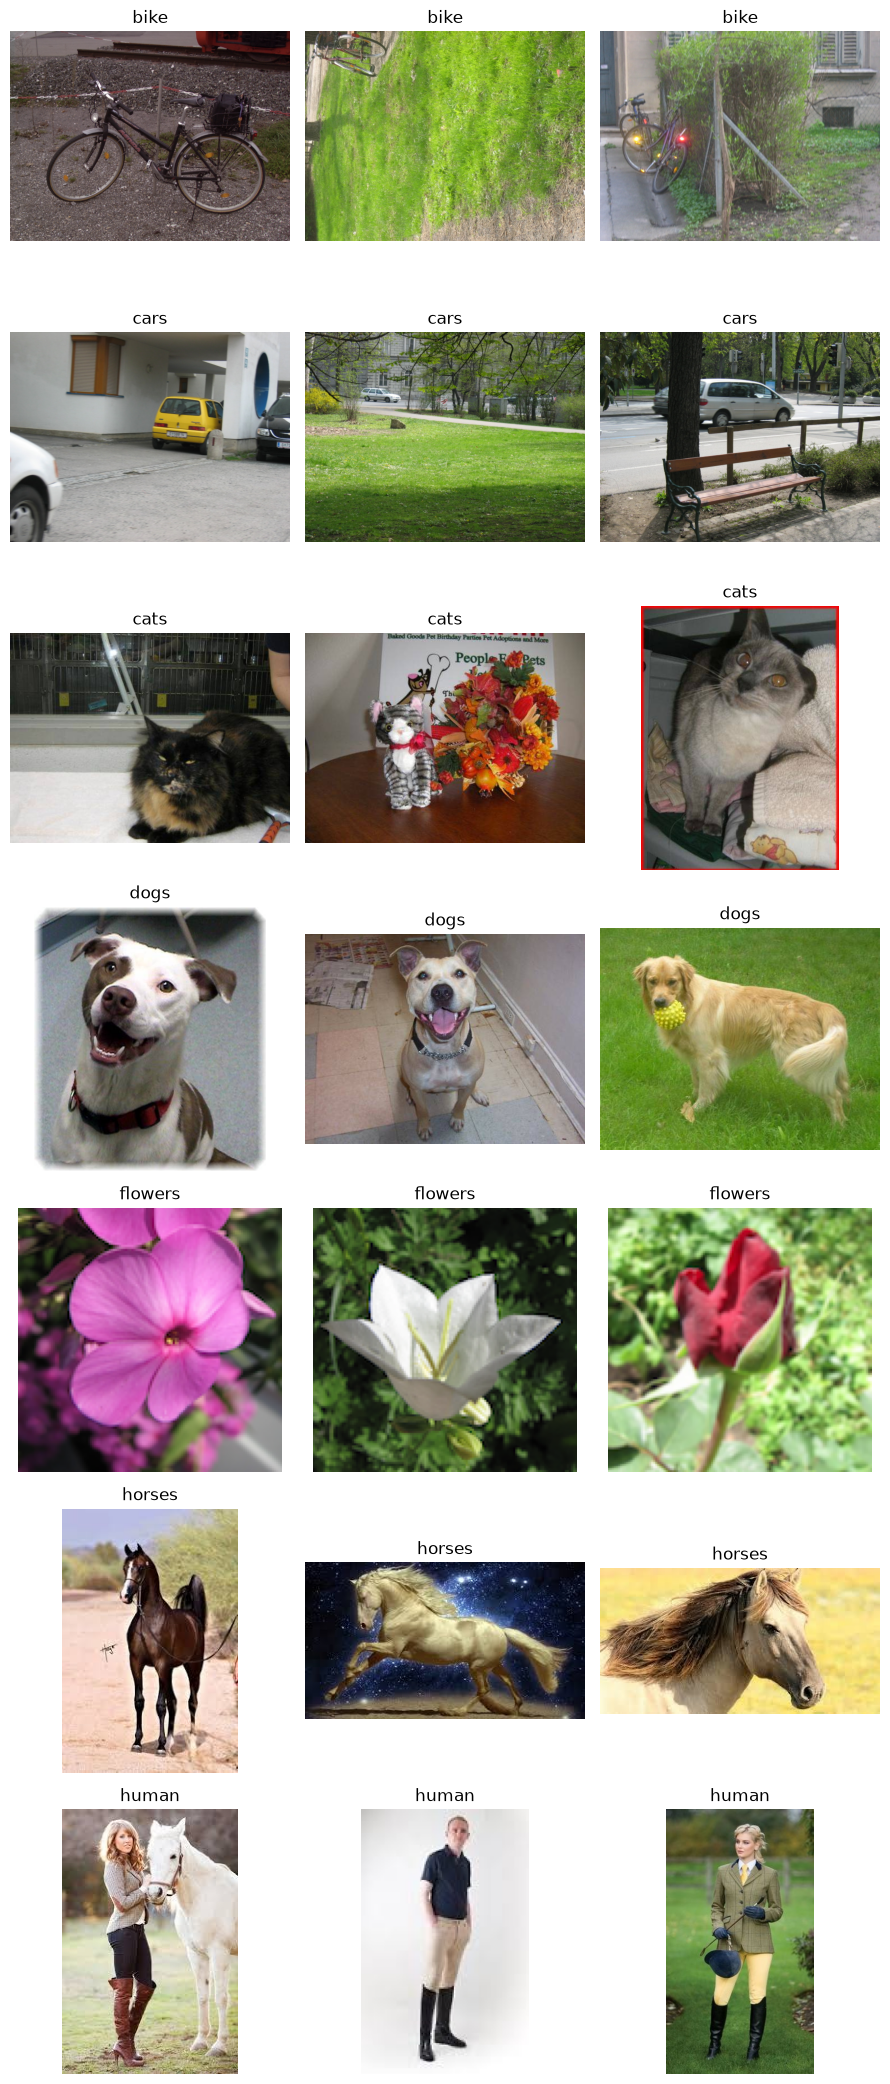

In [6]:
exemplos_por_classe = min(3, int(contagens_classes.min()))
dados_galeria = (
    dados_imagens.groupby("class_name", group_keys=False)
    .sample(n=exemplos_por_classe, random_state=SEMENTE_ALEATORIA)
    .reset_index(drop=True)
)
figura, eixos = plt.subplots(QUANTIDADE_CLASSES, exemplos_por_classe, figsize=(3 * exemplos_por_classe, 3 * QUANTIDADE_CLASSES))
eixos = np.asarray(eixos).reshape(QUANTIDADE_CLASSES, exemplos_por_classe)
for eixo, (_, registro) in zip(eixos.flat, dados_galeria.iterrows()):
    with Image.open(registro.path) as imagem:
        eixo.imshow(imagem.convert("RGB"))
    eixo.set_title(registro.class_name)
    eixo.axis("off")
plt.tight_layout()
plt.show()

# A galeria mostra diferenças de orientação, enquadramento, iluminação e contexto.
# Em cats há uma figura decorativa; em horses, uma ilustração; em human, uma pessoa junto a um cavalo.
# Os três exemplos por classe cobrem apenas parte da diversidade do corpus.


## 4. Divisão estratificada e preparação dos batches

Separamos o teste primeiro e retiramos a validação dos dados restantes. A divisão usa semente 42 e proporções-alvo de 70% para treino, 15% para validação e 15% para teste. Com 1.803 imagens, o arredondamento estratificado resulta em 1.261, 271 e 271 imagens, respectivamente. O pré-processamento converte para RGB, redimensiona para 224 × 224 e aplica a normalização ImageNet. O experimento-base não usa augmentation.

In [7]:
FRACAO_TESTE = 0.15
FRACAO_VALIDACAO = 0.15

# Retiramos a validação dos 85% restantes, usando a fração relativa 0,15 / 0,85.
if (contagens_classes < 3).any():
    raise ValueError("Não é possível manter todas as classes em treino, validação e teste com menos de três amostras por classe.")

dados_treino_validacao, dados_teste = train_test_split(
    dados_imagens, test_size=FRACAO_TESTE, stratify=dados_imagens.class_id, random_state=SEMENTE_ALEATORIA
)
dados_treino, dados_validacao = train_test_split(
    dados_treino_validacao, test_size=FRACAO_VALIDACAO / (1 - FRACAO_TESTE), stratify=dados_treino_validacao.class_id, random_state=SEMENTE_ALEATORIA
)
dados_treino = dados_treino.reset_index(drop=True)
dados_validacao = dados_validacao.reset_index(drop=True)
dados_teste = dados_teste.reset_index(drop=True)

caminhos_particoes = {"treino": set(dados_treino.path), "validação": set(dados_validacao.path), "teste": set(dados_teste.path)}
if any(caminhos_particoes[esquerda] & caminhos_particoes[direita] for esquerda, direita in [("treino", "validação"), ("treino", "teste"), ("validação", "teste")]):
    raise AssertionError("Contrato violado: há interseção de caminhos entre splits.")
for nome_particao, dados_particao in [("treino", dados_treino), ("validação", dados_validacao), ("teste", dados_teste)]:
    classes_ausentes = set(NOMES_CLASSES) - set(dados_particao.class_name)
    if classes_ausentes:
        raise AssertionError(f"Split {nome_particao} sem classes: {sorted(classes_ausentes)}")


### 4.1. Pré-processamento e Dataset

Convertemos as imagens para RGB, redimensionamos para 224 × 224 e normalizamos com os valores do ImageNet, compatíveis com o pré-treinamento. Mantemos o resize do baseline. Usar o preset completo dos pesos, que pode incluir recorte, mudaria o experimento. Esta etapa não aplica augmentation.

In [8]:
# Usamos os valores associados aos pesos ImageNet, sem estimá-los neste corpus.
MEDIA_IMAGENET = (0.485, 0.456, 0.406)
DESVIO_IMAGENET = (0.229, 0.224, 0.225)
transformacao_base = transforms.Compose([
    transforms.Lambda(lambda imagem: imagem.convert("RGB")),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, DESVIO_IMAGENET),
])

class DatasetObjetos(Dataset):
    """Carrega sob demanda e retorna tensor, rótulo e caminho para auditoria."""
    def __init__(self, dados, transformacao):
        self.dados = dados.reset_index(drop=True).copy()
        self.transformacao = transformacao

    def __len__(self):
        return len(self.dados)

    def __getitem__(self, indice):
        registro = self.dados.iloc[indice]
        caminho = registro.path
        with Image.open(caminho) as imagem:
            tensor_imagem = self.transformacao(imagem)
        return tensor_imagem, int(registro.class_id), caminho


### 4.2. DataLoaders e conferência de entrada

Usamos batches de 32 e embaralhamos apenas o treino, mantendo o batch size do experimento-base. No Windows, zero workers evita problemas de serialização nos notebooks. Conferimos a entrada com uma imagem de treino, sem percorrer o loader de teste.

In [9]:
TAMANHO_LOTE = 32  # Mantemos o batch size para preservar a otimização do experimento-base.
# No Windows, workers adicionais usam spawn e podem travar ao serializar o Dataset ou as transformações.
# Como o dataset é pequeno, usamos execução local confiável e paralelismo nos ambientes POSIX.
QUANTIDADE_PROCESSOS = 0 if os.name == "nt" else min(8, max(1, (os.cpu_count() or 1) - 2))
conjunto_treino = DatasetObjetos(dados_treino, transformacao_base)
conjunto_validacao = DatasetObjetos(dados_validacao, transformacao_base)
conjunto_teste = DatasetObjetos(dados_teste, transformacao_base)
gerador_carregador = torch.Generator().manual_seed(SEMENTE_ALEATORIA)
argumentos_carregador = {
    "num_workers": QUANTIDADE_PROCESSOS,
    "pin_memory": True,
    "persistent_workers": QUANTIDADE_PROCESSOS > 0,
    "prefetch_factor": 4 if QUANTIDADE_PROCESSOS > 0 else None,
}
carregador_treino = DataLoader(conjunto_treino, batch_size=TAMANHO_LOTE, shuffle=True, generator=gerador_carregador, **argumentos_carregador)
carregador_validacao = DataLoader(conjunto_validacao, batch_size=TAMANHO_LOTE, shuffle=False, **argumentos_carregador)
carregador_teste = DataLoader(conjunto_teste, batch_size=TAMANHO_LOTE, shuffle=False, **argumentos_carregador)
print(f"DataLoader configurado: batch={TAMANHO_LOTE}, workers={QUANTIDADE_PROCESSOS}, pin_memory=True")

tensor_imagem, indice_classe, caminho = conjunto_treino[0]
assert tensor_imagem.shape == (3, 224, 224), f"Shape inesperado: {tuple(tensor_imagem.shape)}"
assert indice_classe in INDICE_PARA_CLASSE and isinstance(caminho, str)
print(f"Splits — treino: {len(dados_treino)}, validação: {len(dados_validacao)}, teste: {len(dados_teste)}")
print(f"Tensor validado: {tuple(tensor_imagem.shape)} | sem augmentation no treino-base.")


DataLoader configurado: batch=32, workers=0, pin_memory=True
Splits — treino: 1261, validação: 271, teste: 271
Tensor validado: (3, 224, 224) | sem augmentation no treino-base.


## 5. ResNet-50 pré-treinada e feature extraction

Carregamos `ResNet50_Weights.IMAGENET1K_V2`, congelamos os parâmetros existentes e substituímos `fc` por uma camada linear com `QUANTIDADE_CLASSES` saídas. O otimizador ajusta apenas essa cabeça. A BatchNorm do backbone fica em avaliação para preservar suas estatísticas durante o treino.

### Escolha do modelo, das classes e do hardware

As 1.803 imagens incluem objetos, animais, flores e pessoas, próximos ao domínio de imagens naturais do ImageNet. Com poucos dados, começamos reutilizando características pré-treinadas. A ResNet-50 fornece vetores de 2.048 características para a cabeça. As sete classes da execução salva foram descobertas na auditoria, sem lista fixa na construção do modelo.

O experimento foi executado na NVIDIA GeForce RTX 3050 6GB Laptop GPU, com batches de 32, imagens de 224 × 224 e mixed precision. Os registros trazem tempos e memória medidos nessa configuração. Eles não garantem o mesmo consumo ou ausência de OOM em outra configuração. O hardware local segue a orientação que dispensou T4.

ResNet-18 e EfficientNet-B0 são alternativas para comparar custo e accuracy, mas não foram treinadas aqui. A dimensão das características, sozinha, não demonstra maior separabilidade ou superioridade da ResNet-50.

In [10]:
# Congelamos os parâmetros antes de trocar fc; assim, apenas a nova cabeça recebe atualizações.
modelo = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
for parametro in modelo.parameters():
    parametro.requires_grad = False

modelo.fc = nn.Linear(modelo.fc.in_features, QUANTIDADE_CLASSES)
modelo = modelo.to(DISPOSITIVO)
funcao_perda = nn.CrossEntropyLoss()
otimizador = torch.optim.AdamW(modelo.fc.parameters(), lr=1e-3, weight_decay=1e-4)

parametros_treinaveis = {nome: parametro for nome, parametro in modelo.named_parameters() if parametro.requires_grad}
parametros_treinaveis_esperados = {"fc.weight", "fc.bias"}
if set(parametros_treinaveis) != parametros_treinaveis_esperados:
    raise AssertionError(f"Parâmetros treináveis incorretos: {sorted(parametros_treinaveis)}")
if any(parametro.requires_grad for nome, parametro in modelo.named_parameters() if not nome.startswith("fc.")):
    raise AssertionError("O backbone da ResNet-50 deve permanecer congelado.")

modelo.eval()
with torch.inference_mode():
    logits_verificacao = modelo(torch.zeros(2, 3, 224, 224, device=DISPOSITIVO))
assert logits_verificacao.shape == (2, QUANTIDADE_CLASSES), f"Logits com shape inesperado: {tuple(logits_verificacao.shape)}"
print(f"ResNet-50 pronta: apenas {sorted(parametros_treinaveis)} são treináveis.")
print(f"Contrato de logits validado: {tuple(logits_verificacao.shape)}")


ResNet-50 pronta: apenas ['fc.bias', 'fc.weight'] são treináveis.
Contrato de logits validado: (2, 7)


## 6. Treino da cabeça classificadora

AdamW ajusta apenas a cabeça por até 20 épocas. Usamos cross-entropy como perda e escolhemos o estado pela accuracy de validação, com paciência de cinco épocas. CUDA permite mixed precision; o teste permanece reservado.

Esta execução durou 7 épocas. O estado escolhido foi o da época 2, com accuracy de validação de 100.0000%. Os gráficos incluem todas as épocas, mesmo as posteriores ao checkpoint selecionado.

In [11]:
QUANTIDADE_EPOCAS = 20
PACIENCIA_PARADA = 5
PRECISAO_MISTA_ATIVADA = DISPOSITIVO.type == "cuda"
escalador = torch.amp.GradScaler("cuda", enabled=PRECISAO_MISTA_ATIVADA)
parametros_congelados = [parametro for nome, parametro in modelo.named_parameters() if not nome.startswith("fc.")]

def configurar_feature_extraction(modelo):
    """Mantém a BatchNorm congelada enquanto a cabeça recebe atualizações."""
    modelo.train()
    for modulo in modelo.modules():
        if isinstance(modulo, nn.BatchNorm2d):
            modulo.eval()
    modelo.fc.train()


### Executar uma época

Atualizamos apenas a cabeça classificadora. Medimos a duração e o pico de memória da época, sem instrumentar cada batch.

In [12]:
def executar_epoca_treino(modelo, carregador):
    configurar_feature_extraction(modelo)
    perda_total, total_acertos, quantidade_exemplos = 0.0, 0, 0
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    inicio_epoca = time.perf_counter()
    for imagens, rotulos, _ in tqdm(carregador, desc="Treino", leave=False):
        imagens = imagens.to(DISPOSITIVO, non_blocking=True)
        rotulos = rotulos.to(DISPOSITIVO, non_blocking=True)
        otimizador.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=PRECISAO_MISTA_ATIVADA):
            logits = modelo(imagens)
            perda = funcao_perda(logits, rotulos)
        escalador.scale(perda).backward()
        assert all(parametro.grad is None for parametro in parametros_congelados)
        escalador.step(otimizador)
        escalador.update()
        perda_total += perda.detach().item() * rotulos.size(0)
        total_acertos += (logits.argmax(1) == rotulos).sum().item()
        quantidade_exemplos += rotulos.size(0)
    torch.cuda.synchronize()
    duracao = time.perf_counter() - inicio_epoca
    memoria = torch.cuda.max_memory_allocated() / 2**20
    print(f"Treino: {duracao:.2f}s | pico de memória PyTorch: {memoria:.0f} MiB")
    return perda_total / quantidade_exemplos, total_acertos / quantidade_exemplos


### Avaliar a validação

Calculamos loss e accuracy sem gradientes. A validação orienta a escolha do checkpoint.

In [13]:
def avaliar_validacao(modelo, carregador):
    modelo.eval()
    perda_total, total_acertos, quantidade_exemplos = 0.0, 0, 0
    with torch.inference_mode():
        for imagens, rotulos, _ in tqdm(carregador, desc="Validação", leave=False):
            imagens = imagens.to(DISPOSITIVO, non_blocking=True)
            rotulos = rotulos.to(DISPOSITIVO, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=PRECISAO_MISTA_ATIVADA):
                logits = modelo(imagens)
                perda = funcao_perda(logits, rotulos)
            perda_total += perda.item() * rotulos.size(0)
            total_acertos += (logits.argmax(1) == rotulos).sum().item()
            quantidade_exemplos += rotulos.size(0)
    return perda_total / quantidade_exemplos, total_acertos / quantidade_exemplos


### Selecionar o melhor estado

Guardamos o estado de maior accuracy de validação e encerramos após cinco épocas sem melhora. Restauramos esse estado antes da avaliação final.

In [14]:
historico = []
melhor_acuracia_validacao, melhor_estado = float("-inf"), None
epocas_sem_melhora = 0
for epoca in range(1, QUANTIDADE_EPOCAS + 1):
    perda_treino, acuracia_treino = executar_epoca_treino(modelo, carregador_treino)
    perda_validacao, acuracia_validacao = avaliar_validacao(modelo, carregador_validacao)
    historico.append({"epoch": epoca, "train_loss": perda_treino, "train_accuracy": acuracia_treino,
                    "val_loss": perda_validacao, "val_accuracy": acuracia_validacao})
    if acuracia_validacao > melhor_acuracia_validacao:
        melhor_acuracia_validacao = acuracia_validacao
        melhor_estado = copy.deepcopy(modelo.state_dict())
        epocas_sem_melhora = 0
    else:
        epocas_sem_melhora += 1
    print(f"Época {epoca:02d}: treino={acuracia_treino:.4f}, validação={acuracia_validacao:.4f}")
    if epocas_sem_melhora >= PACIENCIA_PARADA:
        print("Early stopping: cinco épocas sem melhora na accuracy de validação.")
        break
assert melhor_estado is not None
modelo.load_state_dict(melhor_estado)
historico_treino = pd.DataFrame(historico)
display(historico_treino)


Treino:   0%|          | 0/40 [00:00<?, ?it/s]

Treino: 7.88s | pico de memória PyTorch: 447 MiB


Validação:   0%|          | 0/9 [00:00<?, ?it/s]

Época 01: treino=0.8898, validação=0.9963


Treino:   0%|          | 0/40 [00:00<?, ?it/s]

...

Treino:   0%|          | 0/40 [00:00<?, ?it/s]

Treino: 6.77s | pico de memória PyTorch: 392 MiB


Validação:   0%|          | 0/9 [00:00<?, ?it/s]

Época 07: treino=0.9992, validação=0.9963
Early stopping: cinco épocas sem melhora na accuracy de validação.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.817460,0.889770,0.277401,0.99631
1,2,0.171479,0.992070,0.131093,1.00000
2,3,0.092504,0.995242,0.089078,0.99631
3,4,0.062710,0.996828,0.068760,0.99631
4,5,0.046437,0.998414,0.055399,0.99631
5,6,0.036347,0.998414,0.046769,0.99631
6,7,0.029438,0.999207,0.040488,0.99631


### Curvas de treino e validação

Exibimos loss e accuracy de todas as épocas, inclusive as posteriores ao checkpoint escolhido. A seleção continua baseada na accuracy de validação, mesmo se a loss diminuir depois.

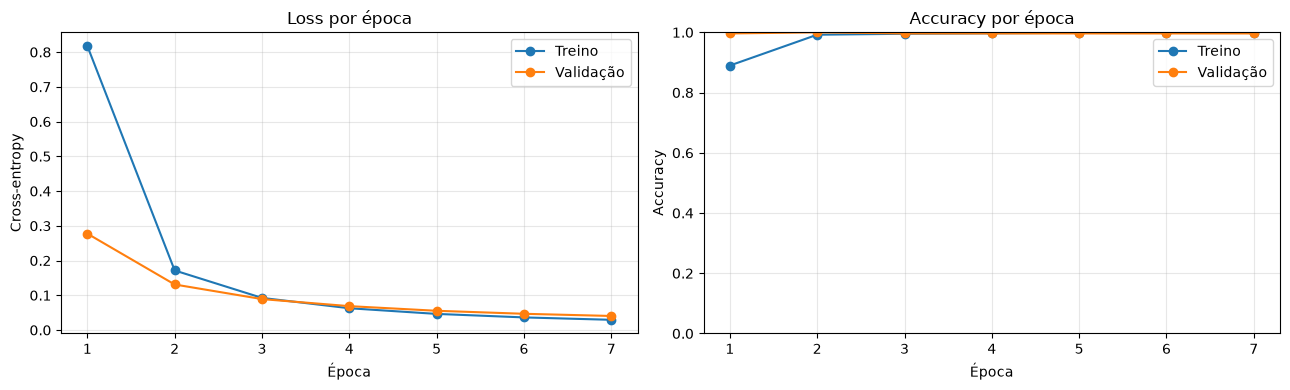

In [15]:
figura, eixos = plt.subplots(1, 2, figsize=(13, 4))
for prefixo, titulo in (("train", "Treino"), ("val", "Validação")):
    eixos[0].plot(historico_treino.epoch, historico_treino[f"{prefixo}_loss"], marker="o", label=titulo)
    eixos[1].plot(historico_treino.epoch, historico_treino[f"{prefixo}_accuracy"], marker="o", label=titulo)
eixos[0].set(title="Loss por época", xlabel="Época", ylabel="Cross-entropy")
eixos[1].set(title="Accuracy por época", xlabel="Época", ylabel="Accuracy", ylim=(0, 1))

for eixo in eixos:
    eixo.grid(alpha=0.3)
    eixo.legend()
plt.tight_layout()
CAMINHO_RESULTADOS = Path("resultados/v2")
CAMINHO_RESULTADOS.mkdir(parents=True, exist_ok=True)
figura.savefig(CAMINHO_RESULTADOS / "curvas.png", dpi=120)
plt.show()


## 7. Avaliação final no teste

Avaliamos o estado escolhido pela validação uma única vez, sem gradientes. A accuracy por classe divide os acertos pelo número de exemplos reais dessa classe e equivale ao recall.

Na execução v2, o modelo acertou 270/271 imagens (99.6310%).

| Classe | Accuracy de teste |
|---|---:|
| bike | 98.1818% |
| cars | 100.0000% |
| cats | 100.0000% |
| dogs | 100.0000% |
| flowers | 100.0000% |
| horses | 100.0000% |
| human | 100.0000% |

A matriz identifica as classes confundidas, mas não explica a causa visual dos erros. Como o relatório pode arredondar os valores, confira também as contagens e métricas completas. O desempenho nesta divisão ainda precisa ser confirmado em dados externos.

Teste:   0%|          | 0/9 [00:00<?, ?it/s]

Accuracy global de teste: 0.9963


,test_accuracy
bike,0.981818
cars,1.000000
cats,1.000000
dogs,1.000000
flowers,1.000000
horses,1.000000
human,1.000000


Relatório de classificação:

              precision    recall  f1-score   support

        bike       1.00      0.98      0.99        55
        cars       0.98      1.00      0.99        63
        cats       1.00      1.00      1.00        30
        dogs       1.00      1.00      1.00        30
     flowers       1.00      1.00      1.00        32
      horses       1.00      1.00      1.00        31
       human       1.00      1.00      1.00        30

    accuracy                           1.00       271
   macro avg       1.00      1.00      1.00       271
weighted avg       1.00      1.00      1.00       271



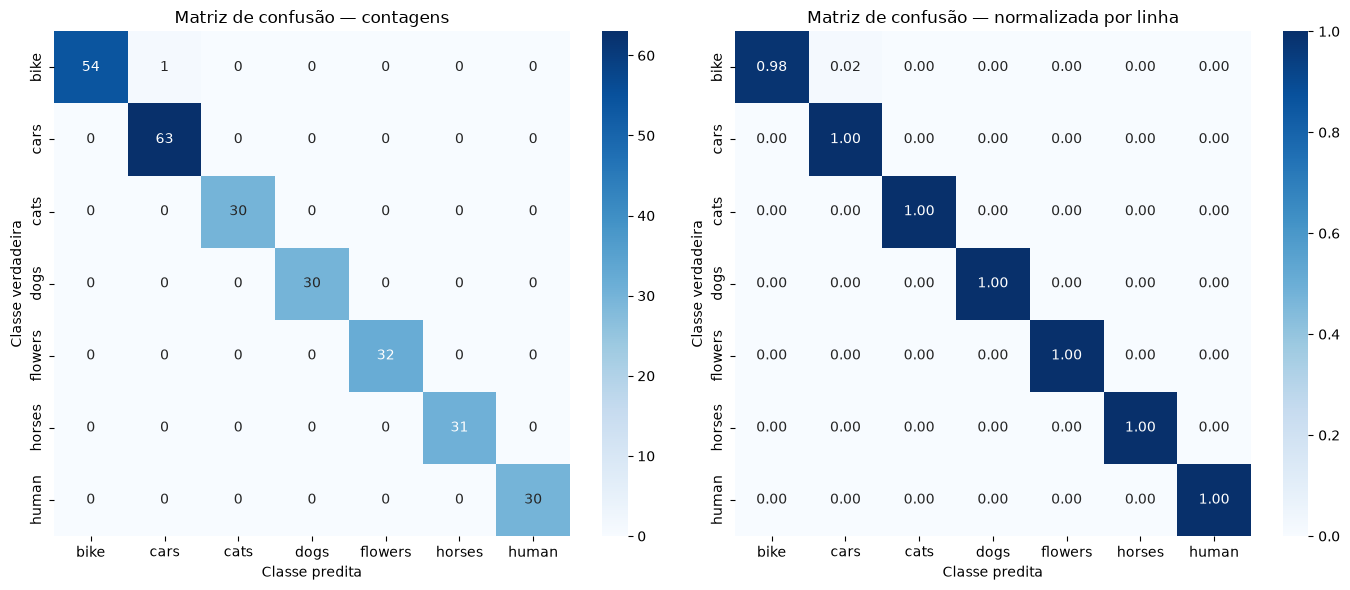

In [16]:
modelo.eval()
rotulos_reais, rotulos_previstos, caminhos_teste = [], [], []
with torch.inference_mode():
    for imagens, rotulos, caminhos in tqdm(carregador_teste, desc="Teste"):
        imagens = imagens.to(DISPOSITIVO, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=PRECISAO_MISTA_ATIVADA):
            logits = modelo(imagens)
        rotulos_reais.extend(rotulos.tolist())
        rotulos_previstos.extend(logits.argmax(dim=1).cpu().tolist())
        caminhos_teste.extend(caminhos)

if len(rotulos_reais) != len(dados_teste) or len(caminhos_teste) != len(dados_teste):
    raise AssertionError("A inferência do teste não cobriu todos os exemplos esperados.")
rotulos_teste = list(range(QUANTIDADE_CLASSES))
contagens_reais = np.bincount(rotulos_reais, minlength=QUANTIDADE_CLASSES)
if (contagens_reais == 0).any():
    classes_ausentes = [INDICE_PARA_CLASSE[indice_classe] for indice_classe in np.flatnonzero(contagens_reais == 0)]
    raise AssertionError(f"Falha do split: classes sem exemplos no teste: {classes_ausentes}")

acuracia_teste = accuracy_score(rotulos_reais, rotulos_previstos)
matriz_confusao = confusion_matrix(rotulos_reais, rotulos_previstos, labels=rotulos_teste)
# A accuracy de cada classe é acertos / exemplos verdadeiros da classe, equivalente ao recall.
acuracia_por_classe = pd.Series(
    matriz_confusao.diagonal() / contagens_reais, index=NOMES_CLASSES, name="test_accuracy"
)
relatorio = classification_report(rotulos_reais, rotulos_previstos, labels=rotulos_teste, target_names=NOMES_CLASSES, zero_division=0)

print(f"Accuracy global de teste: {acuracia_teste:.4f}")
display(acuracia_por_classe.to_frame())
print("Relatório de classificação:\n")
print(relatorio)

figura, eixos = plt.subplots(1, 2, figsize=(max(14, QUANTIDADE_CLASSES * 1.5), 6))
sns.heatmap(matriz_confusao, annot=True, fmt="d", cmap="Blues", xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES, ax=eixos[0])
eixos[0].set(title="Matriz de confusão — contagens", xlabel="Classe predita", ylabel="Classe verdadeira")
sns.heatmap(matriz_confusao / contagens_reais[:, None], annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues", xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES, ax=eixos[1])
eixos[1].set(title="Matriz de confusão — normalizada por linha", xlabel="Classe predita", ylabel="Classe verdadeira")
plt.tight_layout()
plt.show()


## 8. Propostas de melhoria e limitações

### Observações da execução salva

As observações abaixo vêm da inspeção de três imagens por classe. Atualize-as se a galeria ou os dados mudarem.

| Classe observada | Evidência na galeria salva |
|---|---|
| bike | Bicicletas em cenas externas; um exemplo está girado e outro tem obstrução por vegetação. |
| cars | Carros em ruas, vistos lateralmente ou de trás; há carro distante e oclusões por árvores. |
| cats | Gatos com pelagens/fundos distintos e uma figura decorativa de gato junto a flores. |
| dogs | Há aproximações do rosto e cão de corpo inteiro na grama, com pelagens e luz distintas. |
| flowers | Flores rosa, branca e vermelha, com formas distintas e folhagem ao fundo. |
| horses | Cavalo de corpo inteiro, aproximação da cabeça e ilustração de cavalo em movimento. |
| human | Pessoas de corpo inteiro, com roupas e fundos distintos; uma aparece junto a um cavalo. |

### Estratégias de augmentation para este domínio

O baseline não recebeu as transformações propostas abaixo. Seus benefícios ainda precisam ser testados, e a matriz de confusão não permite atribuir os erros a causas visuais específicas.

| Estratégia | Justificativa específica | Risco e ablação proposta |
|---|---|---|
| Flip horizontal | Veículos, animais e pessoas variam de orientação. | Testar `p=0,5` isoladamente; conferir se texto ou sinais direcionais tornam a inversão inadequada. |
| Rotação leve | Poses e orientação variam, inclusive nas bicicletas da galeria. | Testar até 10°; não esperar que cubra rotações extremas. Rotação forte pode gerar posturas pouco plausíveis. |
| Color jitter | Iluminação, pelagens, roupas e fundos variam; perturbações moderadas podem reduzir dependência dessas cores. | Testar brilho/contraste/saturação até 0,1. Alterações fortes podem apagar contornos e contraste entre flores e folhagem. |
| Recorte com variação de escala | Animais aparecem em aproximação e de corpo inteiro; veículos ocupam áreas diferentes da cena. | Testar área de 80–100%, saída 224 × 224; conferir se o objeto permanece visível. Em `human`, o recorte pode retirar a pessoa e manter só o cavalo. |

Grayscale e multi-scale também podem ser testados separadamente. Grayscale pode apagar contrastes das flores, e uma resolução menor pode eliminar objetos pequenos. A normalização ImageNet já faz parte do pré-processamento; não é augmentation, e seu efeito isolado não foi medido.

Compare cada proposta com o baseline de forma isolada, mantendo a divisão, a semente e a seleção pela accuracy de validação. Examine as métricas por classe. Como já consultamos o teste atual, o candidato escolhido precisa ser confirmado em um teste independente. Essas comparações ainda não foram executadas.

### Feature extraction versus fine-tuning

| Tamanho e domínio | Ponto de partida e motivo |
|---|---|
| Poucos dados, domínio próximo ao pré-treinamento | Feature extraction reduz os parâmetros ajustados e pode aproveitar características já úteis. É o caso deste projeto. |
| Mais dados, domínio próximo | Comparar fine-tuning dos últimos blocos, com taxa de aprendizado menor no backbone; mais exemplos permitem adaptar as características. |
| Poucos dados, domínio distante | Avaliar pesos de um domínio mais próximo e fine-tuning gradual com regularização. Congelar tudo pode limitar a adaptação; descongelar tudo aumenta o risco de overfitting. |
| Muitos dados, domínio distante | Avaliar adaptação ampla e, dependendo dos recursos e da quantidade efetiva de exemplos, treino do zero. Comparar experimentalmente. |

A quantidade de imagens, sozinha, não define o regime de treino. Diversidade, qualidade dos rótulos e exemplos por classe também pesam na decisão. Neste corpus pequeno e próximo ao ImageNet, feature extraction funcionou como baseline: o checkpoint da época 2 obteve 99.6310% no teste. Não comparamos os regimes, então esse resultado não mostra que fine-tuning seria pior nem exclui memorização.

### Limitações

Avaliamos uma arquitetura, uma semente e uma divisão fixa, sem fine-tuning ou teste externo. A ausência de caminhos compartilhados entre partições não exclui duplicatas ou imagens muito semelhantes. O teste tem 30–63 exemplos por classe, e a galeria cobre uma amostra pequena. Precisamos confirmar o desempenho em dados independentes. As causas visuais dos erros e os efeitos das propostas ainda não foram medidos.

## 9. Verificação final

Conferimos os dados em memória, as partições, o pré-processamento, os parâmetros treináveis, os logits e as métricas. Essa verificação independe da pasta em que o notebook foi aberto ou de uma lista fixa de células.

A v2 foi executada novamente em kernel novo na NVIDIA GeForce RTX 3050 6GB Laptop GPU, com PyTorch 2.9.0+cu130. As saídas abaixo são dessa execução. Depois de repetir o experimento, atualize os valores nos textos e as observações sobre a galeria.

In [17]:
assert DISPOSITIVO.type == "cuda" and torch.cuda.is_available()
assert raiz_dataset.is_dir() and len(dados_imagens) == QUANTIDADE_IMAGENS_ESPERADA and dados_imagens.path.is_unique
assert len(NOMES_CLASSES) == QUANTIDADE_CLASSES and set(dados_imagens.class_id) == set(range(QUANTIDADE_CLASSES))
assert (contagens_classes >= 3).all(), "São necessárias ao menos três imagens por classe para os três splits."
assert len(dados_treino) + len(dados_validacao) + len(dados_teste) == len(dados_imagens)
assert not (set(dados_treino.path) & set(dados_validacao.path))
assert not (set(dados_treino.path) & set(dados_teste.path))
assert not (set(dados_validacao.path) & set(dados_teste.path))
assert all(set(dados_particao.class_name) == set(NOMES_CLASSES) for dados_particao in (dados_treino, dados_validacao, dados_teste))

normalizacao = next(transformacao for transformacao in transformacao_base.transforms if isinstance(transformacao, transforms.Normalize))
assert tuple(normalizacao.mean) == MEDIA_IMAGENET and tuple(normalizacao.std) == DESVIO_IMAGENET
augmentations_proibidas = ("RandomHorizontalFlip", "RandomRotation", "ColorJitter", "RandomGrayscale", "RandomCrop", "RandomResizedCrop")
assert not any(type(transformacao).__name__ in augmentations_proibidas for transformacao in transformacao_base.transforms)

assert set(nome for nome, parametro in modelo.named_parameters() if parametro.requires_grad) == {"fc.weight", "fc.bias"}
assert {id(parametro) for grupo in otimizador.param_groups for parametro in grupo["params"]} == {id(modelo.fc.weight), id(modelo.fc.bias)}
configurar_feature_extraction(modelo)
assert all(not modulo.training for modulo in modelo.modules() if isinstance(modulo, nn.BatchNorm2d))
with torch.inference_mode():
    logits_verificacao_final = modelo(torch.zeros(2, 3, 224, 224, device=DISPOSITIVO))
assert logits_verificacao_final.shape == (2, QUANTIDADE_CLASSES)

assert not historico_treino.empty and set(historico_treino.columns) == {"epoch", "train_loss", "train_accuracy", "val_loss", "val_accuracy"}
assert len(rotulos_reais) == len(dados_teste) and len(rotulos_previstos) == len(dados_teste) and len(caminhos_teste) == len(dados_teste)
assert np.isfinite(acuracia_teste) and len(acuracia_por_classe) == QUANTIDADE_CLASSES
# Salva os resultados já calculados, sem percorrer o teste de novo.
assert set(caminhos_teste) == set(dados_teste.path)
assert matriz_confusao.sum() == len(dados_teste)
assert np.isfinite(acuracia_por_classe.to_numpy()).all()
print("Verificação concluída: dados, splits, pré-processamento, modelo e métricas consistentes.")


Verificação concluída: dados, splits, pré-processamento, modelo e métricas consistentes.


### Guardar a execução v2

Salvamos o histórico, as métricas e o hardware registrado. Reutilizamos os resultados em memória, sem executar o teste de novo.

In [18]:
import json
historico_treino.to_csv(CAMINHO_RESULTADOS / "historico.csv", index=False)
acuracia_por_classe.to_csv(CAMINHO_RESULTADOS / "acuracia_por_classe.csv")
registro_resultados = {"acuracia_teste": acuracia_teste, "acertos": int(np.trace(matriz_confusao)), "imagens_teste": len(dados_teste), "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__}
(CAMINHO_RESULTADOS / "resultados.json").write_text(json.dumps(registro_resultados, indent=2), encoding="utf-8")
torch.save(modelo.state_dict(), CAMINHO_RESULTADOS / "resnet50.pt")
